# Pipeline Data IPM & Kemiskinan (P2) Jawa Barat
**Pemeriksaan, penggabungan, dan analisis korelasi 27 kabupaten/kota, 2020–2025**

- **Dataset**: BPS Jawa Barat — Indeks Pembangunan Manusia (IPM) dan Indeks Keparahan Kemiskinan (P2), 27 kabupaten/kota
- **Metode**: EDA, pembersihan, outer join, rekayasa fitur, 13 uji kualitas otomatis, korelasi Pearson & Spearman
- **Bahasa/Tools**: Python 3 · pandas · NumPy · Matplotlib · SciPy

> Dua file CSV mentah dimuat dan diperiksa (EDA Fase A), dibersihkan ke periode 2020–2025, lalu digabung berdasarkan kode wilayah + tahun.
> Data gabungan diberi kolom turunan, diperiksa lagi (EDA Fase B), dan divalidasi 13 uji otomatis sebelum disimpan sebagai master.
> Terakhir, hubungan IPM–P2 dianalisis per tahun dan dibandingkan antara Kota dan Kabupaten.

---

## 1. Import Library & Konfigurasi

### Penjelasan
- Memuat library dan menentukan nama file, folder, serta periode analisis di satu tempat agar mudah diubah.
- `REF` (27 wilayah resmi) dan `KOORDINAT` dipakai nanti untuk validasi dan peta.

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BIRU, MERAH, ABU, HIJAU = "#2563EB", "#DC2626", "#64748B", "#16A34A"

In [61]:
FILE_IPM = "bps-od_21092_indeks_pmbngnn_manusia_menggunakan_uhh_lf_sp2020_b_v1_data.csv"
FILE_P2  = "bps-od_19998_indeks_keparahan_kemiskinan_brdsrkn_kabupatenkota_v1_data.csv"
DATA_DIR, OUT_DIR = "data", "hasil"
TAHUN_AWAL, TAHUN_AKHIR = 2020, 2025
os.makedirs(OUT_DIR, exist_ok=True)

def judul(t, s="="): print("\n" + s * 70 + f"\n{t}\n" + s * 70)

In [62]:
# Referensi resmi 27 kabupaten/kota Jawa Barat (kode BPS -> nama)
REF = {
 "3201":"KABUPATEN BOGOR","3202":"KABUPATEN SUKABUMI","3203":"KABUPATEN CIANJUR","3204":"KABUPATEN BANDUNG",
 "3205":"KABUPATEN GARUT","3206":"KABUPATEN TASIKMALAYA","3207":"KABUPATEN CIAMIS","3208":"KABUPATEN KUNINGAN",
 "3209":"KABUPATEN CIREBON","3210":"KABUPATEN MAJALENGKA","3211":"KABUPATEN SUMEDANG","3212":"KABUPATEN INDRAMAYU",
 "3213":"KABUPATEN SUBANG","3214":"KABUPATEN PURWAKARTA","3215":"KABUPATEN KARAWANG","3216":"KABUPATEN BEKASI",
 "3217":"KABUPATEN BANDUNG BARAT","3218":"KABUPATEN PANGANDARAN","3271":"KOTA BOGOR","3272":"KOTA SUKABUMI",
 "3273":"KOTA BANDUNG","3274":"KOTA CIREBON","3275":"KOTA BEKASI","3276":"KOTA DEPOK","3277":"KOTA CIMAHI",
 "3278":"KOTA TASIKMALAYA","3279":"KOTA BANJAR"}

# Titik koordinat peta tiap wilayah "lintang,bujur"
KOORDINAT = {
 "3201":"-6.54539,107.00178","3202":"-7.07645,106.73466","3203":"-7.05399,107.06924","3204":"-7.06134,107.63429",
 "3205":"-7.21628,107.90149","3206":"-7.42717,108.06842","3207":"-7.31316,108.40489","3208":"-6.98698,108.55382",
 "3209":"-6.76119,108.45642","3210":"-6.80736,108.27879","3211":"-6.85972,107.92071","3212":"-6.44182,108.17647",
 "3213":"-6.56898,107.75874","3214":"-6.55567,107.44213","3215":"-6.30219,107.30461","3216":"-6.20279,107.16492",
 "3217":"-6.89775,107.41243","3218":"-7.6408,108.55673","3271":"-6.59636,106.79732","3272":"-6.91993,106.92651",
 "3273":"-6.92185,107.60708","3274":"-6.7137,108.56085","3275":"-6.23499,106.99454","3276":"-6.40719,106.81584",
 "3277":"-6.87315,107.54231","3278":"-7.32625,108.22012","3279":"-7.36956,108.54152"}

---

## 2. Load Dataset

### Penjelasan
- Membaca kedua file CSV dari folder `data/`, lalu memastikan file tidak tertukar dan kolom wajib tersedia.
- `kode_kabupaten_kota` dibaca sebagai teks agar tidak kehilangan angka nol/format kode.
- Jika ada masalah, notebook berhenti dengan pesan yang jelas — lebih aman daripada lanjut dengan data salah.

In [63]:
def muat(nama, kolom_nilai, kolom_lawan, label):
    for folder in (DATA_DIR, "."):
        if os.path.exists(os.path.join(folder, nama)):
            df = pd.read_csv(os.path.join(folder, nama), dtype={"kode_kabupaten_kota": str}); break
    else:
        raise RuntimeError(f"[GAGAL] File '{nama}' tidak ditemukan di folder '{DATA_DIR}'.")
    if kolom_nilai not in df.columns:
        salah = " File kemungkinan TERTUKAR dengan file lain." if kolom_lawan in df.columns else ""
        raise RuntimeError(f"[GAGAL] '{nama}' bukan file {label} (kolom '{kolom_nilai}' tidak ada).{salah}")
    wajib = {"kode_kabupaten_kota", "nama_kabupaten_kota", "tahun"}
    if wajib - set(df.columns):
        raise RuntimeError(f"[GAGAL] '{nama}' tidak punya kolom {sorted(wajib - set(df.columns))}.")
    print(f"✔ File {label:<4}: {df.shape[0]:>3} baris × {df.shape[1]} kolom")
    return df

ipm_raw = muat(FILE_IPM, "indeks_pembangunan_manusia", "indeks_keparahan_kemiskinan", "IPM")
p2_raw  = muat(FILE_P2,  "indeks_keparahan_kemiskinan", "indeks_pembangunan_manusia", "P2")

✔ File IPM : 162 baris × 8 kolom
✔ File P2  : 594 baris × 8 kolom


---

## 3. Exploratory Data Analysis (EDA) — Fase A: Data Mentah

### Penjelasan
- Memeriksa tiap file apa adanya: ukuran, tahun, duplikat, nilai kosong, dan kecocokan dengan 27 wilayah resmi.
- Tujuan: menemukan masalah data **sebelum** digabung, supaya keputusan pembersihan punya dasar.

### Audit struktur & kualitas

### Penjelasan
- Satu fungsi yang sama dipakai untuk kedua dataset agar hasilnya sebanding.
- Angka ringkas (rata-rata, nilai tengah, terendah, tertinggi) dihitung dari seluruh baris mentah.

In [64]:
def audit(df, nama, kol):
    judul(f"Dataset {nama}", "-")
    kode = set(df["kode_kabupaten_kota"])
    cocok = "✔ ya" if kode == set(REF) else "✘ tidak — selisih: " + str(kode ^ set(REF))
    print(f"{'Jumlah baris':<24}: {len(df)}  ({df['kode_kabupaten_kota'].nunique()} wilayah × {df['tahun'].nunique()} tahun)")
    print(f"{'Rentang tahun':<24}: {df['tahun'].min()} – {df['tahun'].max()}")
    print(f"{'Baris duplikat':<24}: {int(df.duplicated(['kode_kabupaten_kota', 'tahun']).sum())}")
    print(f"{'Nilai kosong':<24}: {int(df[kol].isna().sum())}")
    print(f"{'Cocok 27 wilayah resmi':<24}: {cocok}")
    s = df[kol]
    print("\nRingkasan angka (seluruh baris):")
    print(pd.DataFrame({"Rata-rata": [s.mean()], "Nilai tengah": [s.median()], "Terendah": [s.min()], "Tertinggi": [s.max()]},
                       index=[nama]).round(2).to_string())

audit(ipm_raw, "IPM", "indeks_pembangunan_manusia")
audit(p2_raw,  "P2",  "indeks_keparahan_kemiskinan")


----------------------------------------------------------------------
Dataset IPM
----------------------------------------------------------------------
Jumlah baris            : 162  (27 wilayah × 6 tahun)
Rentang tahun           : 2020 – 2025
Baris duplikat          : 0
Nilai kosong            : 0
Cocok 27 wilayah resmi  : ✔ ya

Ringkasan angka (seluruh baris):
     Rata-rata  Nilai tengah  Terendah  Tertinggi
IPM      73.85         73.03     66.96      84.66

----------------------------------------------------------------------
Dataset P2
----------------------------------------------------------------------
Jumlah baris            : 594  (27 wilayah × 22 tahun)
Rentang tahun           : 2004 – 2025
Baris duplikat          : 0
Nilai kosong            : 0
Cocok 27 wilayah resmi  : ✔ ya

Ringkasan angka (seluruh baris):
    Rata-rata  Nilai tengah  Terendah  Tertinggi
P2       0.39          0.34       0.0       2.22


### Temuan janggal: P2 bernilai 0

### Penjelasan
- Nilai 0 pada indeks kemiskinan hampir mustahil untuk wilayah yang sudah berdiri, jadi perlu dicek wilayah mana saja.
- Pemeriksaan dibatasi sebelum tahun 2015, tempat anomali terlihat pada audit.

In [65]:
nol = p2_raw[(p2_raw["indeks_keparahan_kemiskinan"] == 0) & (p2_raw["tahun"] < 2015)]
print(f"{len(nol)} baris P2 bernilai 0 sebelum 2015, milik:")
for nama, t in nol.groupby("nama_kabupaten_kota")["tahun"].agg(["min", "max"]).iterrows():
    print(f"  - {nama:<26}: {t['min']}–{t['max']}")
print("\nInterpretasi: nilai 0 ini bukan 'tanpa kemiskinan', melainkan kemungkinan wilayah belum terbentuk (pemekaran).")
print("Karena itu dianggap 'belum ada data' dan tidak ikut analisis.")

14 baris P2 bernilai 0 sebelum 2015, milik:
  - KABUPATEN BANDUNG BARAT   : 2004–2006
  - KABUPATEN PANGANDARAN     : 2004–2014

Interpretasi: nilai 0 ini bukan 'tanpa kemiskinan', melainkan kemungkinan wilayah belum terbentuk (pemekaran).
Karena itu dianggap 'belum ada data' dan tidak ikut analisis.


### Chart 1A & 1B — Jumlah kab/kota tercatat per tahun

### Penjelasan
- Dua grafik berdampingan agar kelengkapan kedua file mudah dibandingkan.
- Batang merah pada P2 menandai tahun yang memuat nilai 0; angka di atas batang = jumlah wilayah tercatat.

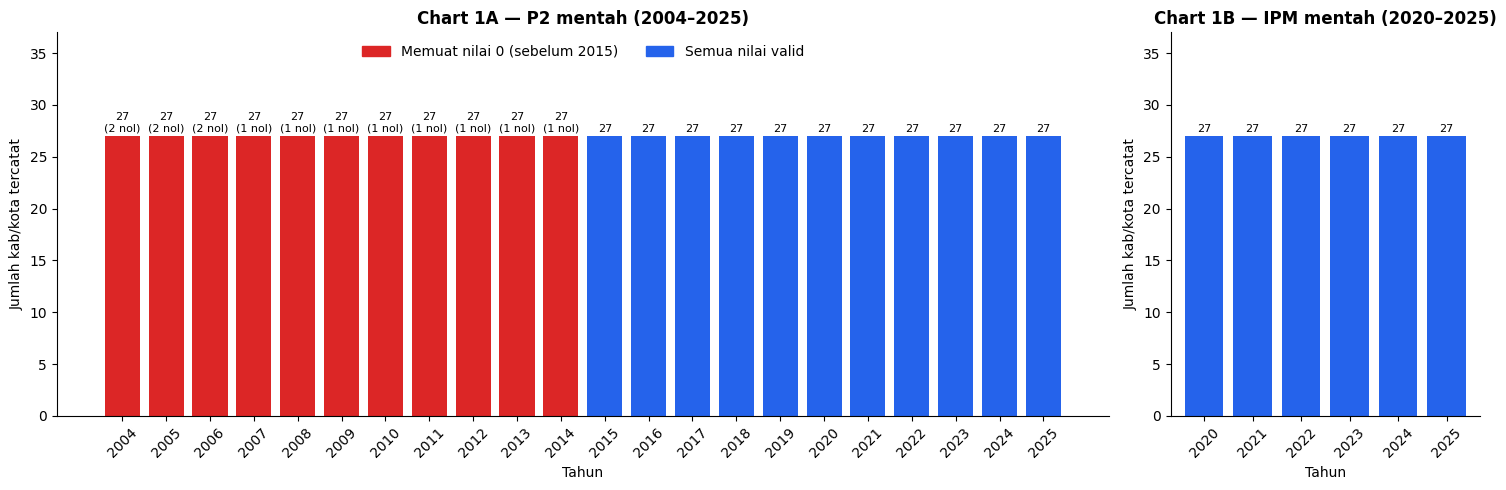

Interpretasi: sebelum 2015, P2 punya 1–2 wilayah bernilai 0 (belum terbentuk); mulai 2015 seluruh 27 wilayah valid.
IPM hanya ada untuk 2020–2025 tetapi lengkap 27 wilayah tiap tahun, tanpa nilai kosong.


In [66]:
def bar_tahun(ax, df, kol, judul_chart, warna, tandai_nol=False):
    n = df.groupby("tahun").size()
    nol = df[df[kol] == 0].groupby("tahun").size().reindex(n.index, fill_value=0)
    warna_bar = [MERAH if (tandai_nol and nol[t] > 0) else warna for t in n.index]
    bars = ax.bar(n.index.astype(str), n.values, color=warna_bar)
    for b, t in zip(bars, n.index):
        ket = f"{int(b.get_height())}" + (f"\n({nol[t]} nol)" if nol[t] > 0 else "")
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, ket, ha="center", fontsize=8)
    ax.set_ylim(0, 37); ax.set_xlabel("Tahun"); ax.set_ylabel("Jumlah kab/kota tercatat")
    ax.set_title(judul_chart, fontweight="bold"); ax.tick_params(axis="x", rotation=45)

fig, axs = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [3.4, 1]})
bar_tahun(axs[0], p2_raw,  "indeks_keparahan_kemiskinan", "Chart 1A — P2 mentah (2004–2025)", BIRU, tandai_nol=True)
bar_tahun(axs[1], ipm_raw, "indeks_pembangunan_manusia",  "Chart 1B — IPM mentah (2020–2025)", BIRU)
axs[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MERAH), plt.Rectangle((0, 0), 1, 1, color=BIRU)],
              labels=["Memuat nilai 0 (sebelum 2015)", "Semua nilai valid"], loc="upper center", ncol=2, frameon=False)
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/chart1ab_data_mentah.png", dpi=300, bbox_inches="tight"); plt.show()

print("Interpretasi: sebelum 2015, P2 punya 1–2 wilayah bernilai 0 (belum terbentuk); mulai 2015 seluruh 27 wilayah valid.")
print("IPM hanya ada untuk 2020–2025 tetapi lengkap 27 wilayah tiap tahun, tanpa nilai kosong.")

### Chart 1C — Kelengkapan data IPM vs P2

### Penjelasan
- Membandingkan jumlah wilayah yang datanya valid per tahun untuk menentukan periode analisis yang sah.
- Nilai P2 = 0 dihitung sebagai 'belum ada data'.

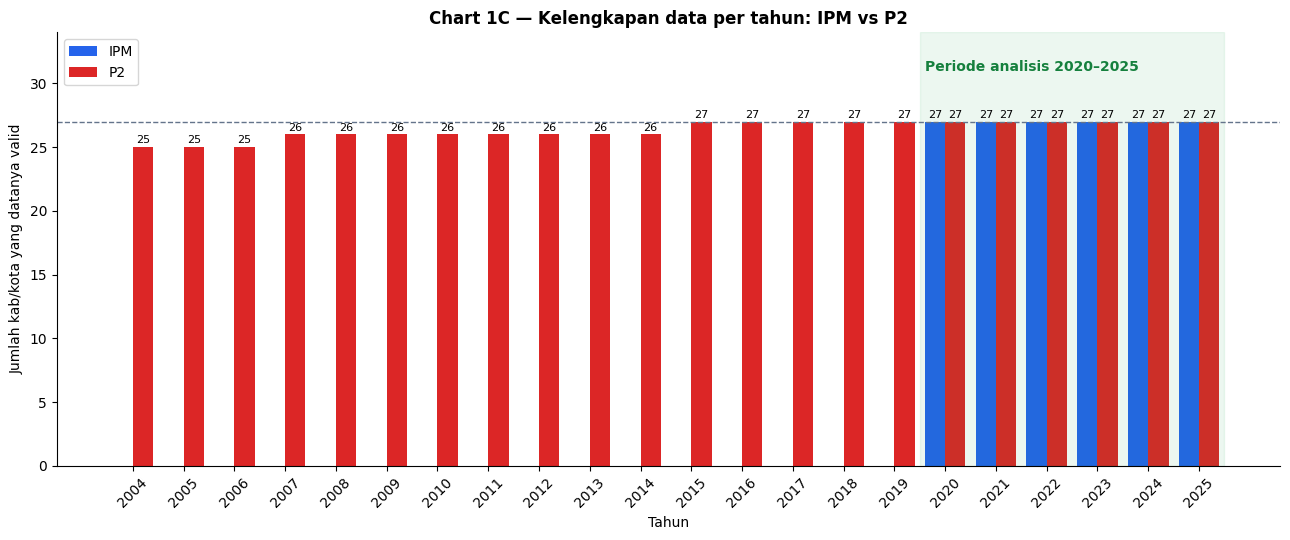

Interpretasi: IPM baru tersedia sejak 2020, sedangkan P2 sejak 2004 (lengkap 27 wilayah sejak 2015).
Analisis dibatasi pada 2020–2025, satu-satunya periode yang punya IPM dan P2 sekaligus untuk 27 wilayah.


In [67]:
tahun = list(range(2004, 2026))
n_ipm = ipm_raw.dropna(subset=["indeks_pembangunan_manusia"]).groupby("tahun")["kode_kabupaten_kota"].nunique().reindex(tahun, fill_value=0)
n_p2  = p2_raw[p2_raw["indeks_keparahan_kemiskinan"] > 0].groupby("tahun")["kode_kabupaten_kota"].nunique().reindex(tahun, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(tahun)); w = 0.4
for off, n, c, lab in [(-w/2, n_ipm, BIRU, "IPM"), (w/2, n_p2, MERAH, "P2")]:
    bars = ax.bar(x + off, n.values, w, color=c, label=lab)
    for b in bars:
        if b.get_height() > 0: ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, int(b.get_height()), ha="center", fontsize=8)
ax.axhline(27, color=ABU, ls="--", lw=1)
ax.axvspan(tahun.index(2020) - 0.5, len(tahun) - 0.5, color=HIJAU, alpha=0.08)
ax.text(tahun.index(2020) - 0.4, 31, "Periode analisis 2020–2025", color="#15803D", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(tahun, rotation=45); ax.set_ylim(0, 34)
ax.set_xlabel("Tahun"); ax.set_ylabel("Jumlah kab/kota yang datanya valid")
ax.set_title("Chart 1C — Kelengkapan data per tahun: IPM vs P2", fontweight="bold"); ax.legend(loc="upper left")
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/chart1c_kelengkapan_data.png", dpi=300, bbox_inches="tight"); plt.show()

print("Interpretasi: IPM baru tersedia sejak 2020, sedangkan P2 sejak 2004 (lengkap 27 wilayah sejak 2015).")
print("Analisis dibatasi pada 2020–2025, satu-satunya periode yang punya IPM dan P2 sekaligus untuk 27 wilayah.")

---

## 4. Data Preprocessing

### Penjelasan
- Menyiapkan kedua dataset mentah agar siap digabung: teks distandarkan, missing value & duplikat ditangani, anomali P2 = 0 dikeluarkan, lalu periode diselaraskan ke 2020–2025.
- Setiap langkah dicatat jumlah barisnya (`jejak`) supaya perubahan sebelum–sesudah bisa dilihat di akhir tahap.
- Penyaringan periode dilakukan **sebelum** merge agar baris P2 lama (2004–2019) tidak ikut terbawa.

### 4.1 Standarisasi teks & pencocokan 27 wilayah resmi

### Penjelasan
- Spasi berlebih pada kode/nama dibuang dan nama dijadikan huruf kapital, lalu dicocokkan dengan `REF`.
- Jika nama berbeda dari referensi, nama resmi `REF` yang dipakai agar konsisten di kedua dataset.

In [68]:
def standar(df, kol, nama):
    d = df.copy()
    for k in ["kode_kabupaten_kota", "nama_kabupaten_kota"]:
        d[k] = d[k].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    d["nama_kabupaten_kota"] = d["nama_kabupaten_kota"].str.upper()
    d["tahun"] = d["tahun"].astype(int)
    return d[["kode_kabupaten_kota", "nama_kabupaten_kota", "tahun", kol]].rename(columns={kol: nama})

ipm_s = standar(ipm_raw, "indeks_pembangunan_manusia", "ipm")
p2_s  = standar(p2_raw,  "indeks_keparahan_kemiskinan", "p2")
jejak = [("Data mentah", len(ipm_raw), len(p2_raw))]

for nama, d in [("IPM", ipm_s), ("P2", p2_s)]:
    kode_asing = set(d["kode_kabupaten_kota"]) - set(REF)
    nama_beda = int((d["kode_kabupaten_kota"].map(REF) != d["nama_kabupaten_kota"]).sum())
    d["nama_kabupaten_kota"] = d["kode_kabupaten_kota"].map(REF)          # nama resmi dari referensi
    print(f"{nama:<4}: kode di luar REF = {len(kode_asing)} | nama berbeda dari REF = {nama_beda} baris (sudah diseragamkan) | "
          f"cocok 27 wilayah: {'✔' if set(d['kode_kabupaten_kota']) == set(REF) else '✘'}")
jejak.append(("Standarisasi teks", len(ipm_s), len(p2_s)))

IPM : kode di luar REF = 0 | nama berbeda dari REF = 0 baris (sudah diseragamkan) | cocok 27 wilayah: ✔
P2  : kode di luar REF = 0 | nama berbeda dari REF = 0 baris (sudah diseragamkan) | cocok 27 wilayah: ✔


### 4.2 Audit & penanganan missing value dan duplikat

### Penjelasan
- Nilai kosong dibuang, dan baris ganda (wilayah + tahun sama) dihapus dengan menyisakan satu.
- Tabel menunjukkan kondisi sebelum dan sesudah, sehingga terlihat apakah langkah ini benar-benar mengubah sesuatu.

In [69]:
def profil(d, kol):
    return {"Baris": len(d), "Nilai kosong": int(d[kol].isna().sum()),
            "Duplikat (wilayah+tahun)": int(d.duplicated(["kode_kabupaten_kota", "tahun"]).sum())}

sebelum = {"IPM": profil(ipm_s, "ipm"), "P2": profil(p2_s, "p2")}
ipm_s = ipm_s.drop_duplicates(["kode_kabupaten_kota", "tahun"]).dropna(subset=["ipm"])
p2_s  = p2_s.drop_duplicates(["kode_kabupaten_kota", "tahun"]).dropna(subset=["p2"])
sesudah = {"IPM": profil(ipm_s, "ipm"), "P2": profil(p2_s, "p2")}

tabel = pd.concat({"Sebelum": pd.DataFrame(sebelum), "Sesudah": pd.DataFrame(sesudah)}, axis=1)
print(tabel.to_string())
jejak.append(("Hapus kosong & duplikat", len(ipm_s), len(p2_s)))
print("\nInterpretasi: kedua dataset tidak punya nilai kosong maupun duplikat, jadi langkah ini tidak mengubah jumlah baris (tetap perlu sebagai pengaman).")

                         Sebelum      Sesudah     
                             IPM   P2     IPM   P2
Baris                        162  594     162  594
Nilai kosong                   0    0       0    0
Duplikat (wilayah+tahun)       0    0       0    0

Interpretasi: kedua dataset tidak punya nilai kosong maupun duplikat, jadi langkah ini tidak mengubah jumlah baris (tetap perlu sebagai pengaman).


### 4.3 Penanganan anomali P2 = 0

### Penjelasan
- P2 = 0 hanya muncul pada wilayah yang belum terbentuk (Kab. Bandung Barat dan Kab. Pangandaran), bukan berarti 'tanpa kemiskinan'.
- Nilai 0 dijadikan kosong (`NaN`) lalu barisnya dikeluarkan, karena memasukkannya akan menarik rata-rata P2 ke bawah.

In [70]:
nol = p2_s["p2"] == 0
print(f"Baris P2 = 0 : {int(nol.sum())}  (sebelum 2015: {int((nol & (p2_s['tahun'] < 2015)).sum())}, 2015 ke atas: {int((nol & (p2_s['tahun'] >= 2015)).sum())})")
for nama, t in p2_s[nol].groupby("nama_kabupaten_kota")["tahun"].agg(["min", "max"]).iterrows():
    print(f"  - {nama:<26}: {t['min']}–{t['max']}")

p2_s.loc[nol, "p2"] = np.nan                   # 0 = 'belum ada data'
p2_s = p2_s.dropna(subset=["p2"])
jejak.append(("Keluarkan P2 = 0", len(ipm_s), len(p2_s)))
print(f"\nSesudah: {len(p2_s)} baris P2 tersisa, nilai terendah kini {p2_s['p2'].min():.2f} (bukan 0).")

Baris P2 = 0 : 14  (sebelum 2015: 14, 2015 ke atas: 0)
  - KABUPATEN BANDUNG BARAT   : 2004–2006
  - KABUPATEN PANGANDARAN     : 2004–2014

Sesudah: 580 baris P2 tersisa, nilai terendah kini 0.03 (bukan 0).


### 4.4 Penyelarasan periode 2020–2025

### Penjelasan
- IPM hanya tersedia sejak 2020, sehingga P2 dipangkas ke periode yang sama agar tiap pasangan IPM–P2 punya data.

In [71]:
ipm = ipm_s[ipm_s["tahun"].between(TAHUN_AWAL, TAHUN_AKHIR)].reset_index(drop=True)
p2  = p2_s[p2_s["tahun"].between(TAHUN_AWAL, TAHUN_AKHIR)].reset_index(drop=True)
jejak.append((f"Periode {TAHUN_AWAL}–{TAHUN_AKHIR}", len(ipm), len(p2)))
print(f"IPM: {len(ipm)} baris | P2: {len(p2)} baris | {ipm['kode_kabupaten_kota'].nunique()} wilayah × {ipm['tahun'].nunique()} tahun")

IPM: 162 baris | P2: 162 baris | 27 wilayah × 6 tahun


### 4.5 Keputusan outlier & validasi akhir sebelum merge

### Penjelasan
- Outlier dicek dengan aturan IQR. Keputusan: **dipertahankan**, karena itu angka asli BPS (bukan salah input) dan korelasi Spearman tetap kuat terhadapnya.
- `assert` memastikan data benar-benar siap digabung; notebook berhenti bila ada yang tidak sesuai.

In [72]:
for nama, d, k in [("IPM", ipm, "ipm"), ("P2", p2, "p2")]:
    q1, q3 = d[k].quantile([.25, .75]); lo_, hi_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    o = d[(d[k] < lo_) | (d[k] > hi_)]
    print(f"{nama:<4}: {len(o)} outlier → dipertahankan" + (" (" + ", ".join(f"{REF[r.kode_kabupaten_kota].title()} {r.tahun}" for r in o.itertuples()) + ")" if len(o) else ""))

for d, k in [(ipm, "ipm"), (p2, "p2")]:
    assert d[k].notna().all(), "Masih ada nilai kosong!"
    assert not d.duplicated(["kode_kabupaten_kota", "tahun"]).any(), "Masih ada duplikat!"
    assert d["kode_kabupaten_kota"].nunique() == 27 and d["tahun"].nunique() == 6, "Cakupan wilayah/tahun tidak lengkap!"
assert (p2["p2"] > 0).all(), "Masih ada P2 = 0!"
print("\n✔ Validasi lulus: tanpa nilai kosong, tanpa duplikat, 27 wilayah × 6 tahun, tidak ada P2 = 0. Siap digabung.")

IPM : 0 outlier → dipertahankan
P2  : 3 outlier → dipertahankan (Kabupaten Majalengka 2021, Kota Cirebon 2021, Kota Tasikmalaya 2021)

✔ Validasi lulus: tanpa nilai kosong, tanpa duplikat, 27 wilayah × 6 tahun, tidak ada P2 = 0. Siap digabung.


### 4.6 Sebelum vs sesudah preprocessing

### Penjelasan
- Kiri: jumlah baris di tiap langkah. Kanan: sebaran P2 sebelum (ada tumpukan nilai 0) dan sesudah.
- Tabel di bawah grafik merangkum perbedaan angka kunci.

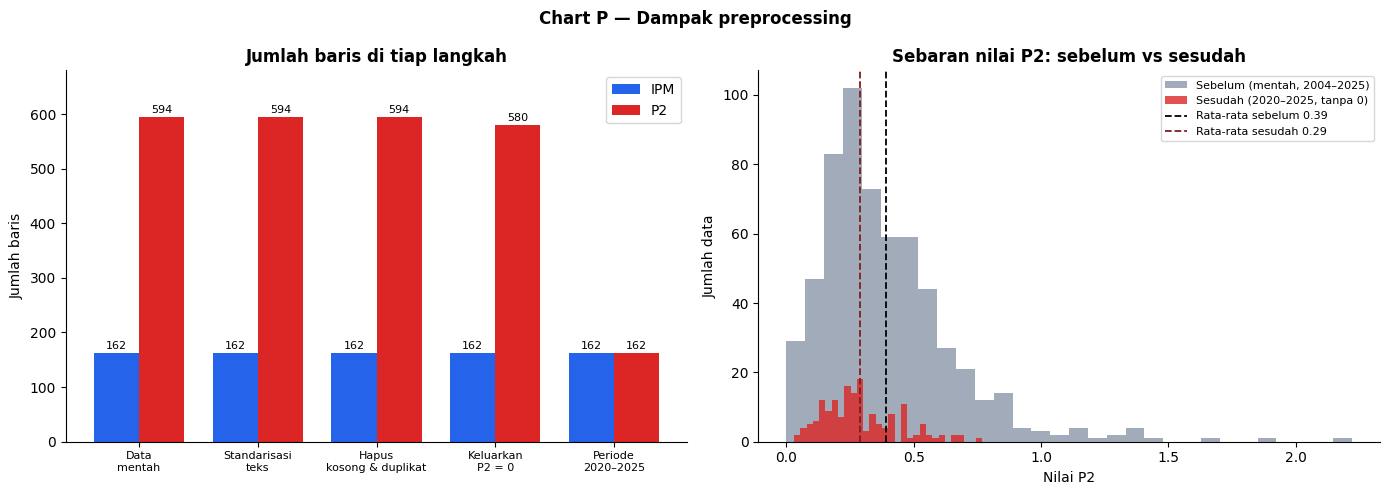

          IPM sebelum IPM sesudah P2 sebelum P2 sesudah
Baris             162         162        594        162
Tahun       2020–2025   2020–2025  2004–2025  2020–2025
Nilai 0             0           0         14          0
Terendah        66.96       66.96        0.0       0.03
Rata-rata       73.85       73.85       0.39       0.29

Interpretasi: IPM hanya berubah dari sisi teks (isi tetap). P2 berkurang dari 594 ke 162 baris dan rata-ratanya turun dari 0.39 ke 0.29, terutama karena tahun 2004–2019 (kemiskinan lebih tinggi) tidak ikut; membuang 14 nilai 0 justru sedikit menaikkan rata-rata.
Catatan: nilai tidak dinormalisasi karena korelasi tidak terpengaruh skala dan angka asli BPS dibutuhkan untuk kategori & status wilayah.


In [73]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
lab = [j[0] for j in jejak]; x = np.arange(len(jejak)); w = 0.38
for off, idx, c, nm in [(-w/2, 1, BIRU, "IPM"), (w/2, 2, MERAH, "P2")]:
    bars = axs[0].bar(x + off, [j[idx] for j in jejak], w, color=c, label=nm)
    for b in bars: axs[0].text(b.get_x() + b.get_width()/2, b.get_height() + 8, int(b.get_height()), ha="center", fontsize=8)
axs[0].set_xticks(x); axs[0].set_xticklabels([l.replace(" ", "\n", 1) for l in lab], fontsize=8)
axs[0].set_ylabel("Jumlah baris"); axs[0].set_ylim(0, 680); axs[0].legend()
axs[0].set_title("Jumlah baris di tiap langkah", fontweight="bold")

axs[1].hist(p2_raw["indeks_keparahan_kemiskinan"], bins=30, color=ABU, alpha=.6, label="Sebelum (mentah, 2004–2025)")
axs[1].hist(p2["p2"], bins=30, color=MERAH, alpha=.8, label="Sesudah (2020–2025, tanpa 0)")
for v, c, nm in [(p2_raw["indeks_keparahan_kemiskinan"], "black", "Sebelum"), (p2["p2"], "#7F1D1D", "Sesudah")]:
    axs[1].axvline(v.mean(), color=c, ls="--", lw=1.3, label=f"Rata-rata {nm.lower()} {v.mean():.2f}")
axs[1].set_xlabel("Nilai P2"); axs[1].set_ylabel("Jumlah data"); axs[1].legend(fontsize=8)
axs[1].set_title("Sebaran nilai P2: sebelum vs sesudah", fontweight="bold")
fig.suptitle("Chart P — Dampak preprocessing", fontweight="bold"); plt.tight_layout()
fig.savefig(f"{OUT_DIR}/chart_preprocessing.png", dpi=300, bbox_inches="tight"); plt.show()

def ringkas_(d, k):
    return {"Baris": len(d), "Tahun": f"{d['tahun'].min()}–{d['tahun'].max()}", "Nilai 0": int((d[k] == 0).sum()),
            "Terendah": round(d[k].min(), 2), "Rata-rata": round(d[k].mean(), 2)}
perbedaan = pd.concat({"IPM sebelum": pd.Series(ringkas_(ipm_raw.rename(columns={"indeks_pembangunan_manusia": "ipm"}), "ipm")),
                       "IPM sesudah": pd.Series(ringkas_(ipm, "ipm")),
                       "P2 sebelum":  pd.Series(ringkas_(p2_raw.rename(columns={"indeks_keparahan_kemiskinan": "p2"}), "p2")),
                       "P2 sesudah":  pd.Series(ringkas_(p2, "p2"))}, axis=1)
print(perbedaan.to_string())
print(f"\nInterpretasi: IPM hanya berubah dari sisi teks (isi tetap). P2 berkurang dari {len(p2_raw)} ke {len(p2)} baris dan rata-ratanya turun "
      f"dari {p2_raw['indeks_keparahan_kemiskinan'].mean():.2f} ke {p2['p2'].mean():.2f}, terutama karena tahun 2004–2019 (kemiskinan lebih tinggi) tidak ikut; "
      f"membuang 14 nilai 0 justru sedikit menaikkan rata-rata.")
print("Catatan: nilai tidak dinormalisasi karena korelasi tidak terpengaruh skala dan angka asli BPS dibutuhkan untuk kategori & status wilayah.")

---

## 5. Merge Dataset IPM dan P2

### Penjelasan
- Menggabungkan dua tabel dengan kunci `kode_kabupaten_kota` + `tahun` (outer join) agar baris yang tidak cocok tetap terlihat.
- `indicator=True` menandai asal tiap baris: `both` = ada di keduanya. Targetnya 162 baris `both` tanpa sisa.

In [74]:
gabung = ipm.merge(p2[["kode_kabupaten_kota", "tahun", "p2"]], on=["kode_kabupaten_kota", "tahun"], how="outer", indicator=True)
asal = gabung["_merge"].astype(str).value_counts().reindex(["both", "left_only", "right_only"], fill_value=0)
print(f"{'Kunci gabung':<14}: kode_kabupaten_kota + tahun")
print(f"{'Sebelum':<14}: IPM {ipm.shape} | P2 {p2.shape}")
print(f"{'Sesudah':<14}: {gabung.shape[0]} baris × {gabung.shape[1]-1} kolom")
print(f"{'Asal baris':<14}: both={asal['both']}, left_only={asal['left_only']}, right_only={asal['right_only']}"
      f"  {'✔ semua cocok' if asal['both'] == len(gabung) else '✘ ada baris tidak cocok'}")
print()
print(gabung.drop(columns="_merge").head(5).to_string(index=False))
print("\nInterpretasi: semua baris cocok di kedua dataset, sehingga tidak ada data yang hilang atau tertinggal saat penggabungan.")

Kunci gabung  : kode_kabupaten_kota + tahun
Sebelum       : IPM (162, 4) | P2 (162, 4)
Sesudah       : 162 baris × 5 kolom
Asal baris    : both=162, left_only=0, right_only=0  ✔ semua cocok

kode_kabupaten_kota nama_kabupaten_kota  tahun   ipm   p2
               3201     KABUPATEN BOGOR   2020 71.63 0.11
               3201     KABUPATEN BOGOR   2021 71.83 0.35
               3201     KABUPATEN BOGOR   2022 72.45 0.45
               3201     KABUPATEN BOGOR   2023 73.02 0.21
               3201     KABUPATEN BOGOR   2024 73.63 0.26

Interpretasi: semua baris cocok di kedua dataset, sehingga tidak ada data yang hilang atau tertinggal saat penggabungan.


---

## 6. Feature Engineering

### Penjelasan
- Menambah kolom turunan: tipe wilayah, kategori IPM (batas BPS 80/70/60), perubahan tahunan (yoy), peringkat, rata-rata kab/kota, dan status wilayah.
- Rata-rata dibulatkan hanya untuk tampilan; status wilayah dan yoy memakai angka asli agar tidak bergeser akibat pembulatan.
- Peringkat 1 = nilai tertinggi (`method='min'`: nilai sama, peringkat sama).

In [75]:
def kategori(v):  # batas kategori IPM menurut BPS
    return "Sangat Tinggi" if v >= 80 else "Tinggi" if v >= 70 else "Sedang" if v >= 60 else "Rendah"

m = gabung.drop(columns="_merge").sort_values(["kode_kabupaten_kota", "tahun"]).reset_index(drop=True)
m["tipe"] = np.where(m["nama_kabupaten_kota"].str.startswith("KOTA"), "Kota", "Kabupaten")
m["nama_label"] = m["nama_kabupaten_kota"].str.title().str.replace(r"^Kabupaten ", "Kab. ", regex=True)
m["tanggal"] = m["tahun"].astype(str) + "-01-01"
m["kategori_ipm"] = m["ipm"].apply(kategori)

In [76]:
for k in ["ipm", "p2"]:
    m[f"{k}_yoy"] = m.groupby("kode_kabupaten_kota")[k].diff().round(2)
    m[f"rank_{k}"] = m.groupby("tahun")[k].rank(ascending=False, method="min").astype(int)   # 1 = tertinggi

rata = m.groupby("tahun")[["ipm", "p2"]].transform("mean")       # nilai asli (belum dibulatkan)
m["ipm_rata2_kabkota"], m["p2_rata2_kabkota"] = rata["ipm"].round(2), rata["p2"].round(2)
tahunan = m.groupby("tahun")[["ipm", "p2"]].mean().diff().round(2)
m["ipm_rata2_kabkota_yoy"], m["p2_rata2_kabkota_yoy"] = m["tahun"].map(tahunan["ipm"]), m["tahun"].map(tahunan["p2"])

# Status: IPM di atas rata-rata & P2 di bawah rata-rata = "Unggul", dst.
hi, lo = m["ipm"] >= rata["ipm"], m["p2"] <= rata["p2"]
m["status_wilayah"] = np.select([hi & lo, hi & ~lo, ~hi & lo], ["Unggul", "Waspada kemiskinan", "Kejar IPM"], default="Tertinggal ganda")
m["koordinat"] = m["kode_kabupaten_kota"].map(KOORDINAT)

In [77]:
master = m[["kode_kabupaten_kota", "nama_label", "tipe", "tahun", "tanggal", "ipm", "p2", "kategori_ipm", "ipm_yoy", "p2_yoy",
            "rank_ipm", "rank_p2", "ipm_rata2_kabkota", "p2_rata2_kabkota", "ipm_rata2_kabkota_yoy", "p2_rata2_kabkota_yoy",
            "status_wilayah", "koordinat"]]
print(f"Data master: {master.shape[0]} baris × {master.shape[1]} kolom\n")
print("Jumlah wilayah per status tiap tahun:")
print(pd.crosstab(master["tahun"], master["status_wilayah"]).to_string())

Data master: 162 baris × 18 kolom

Jumlah wilayah per status tiap tahun:
status_wilayah  Kejar IPM  Tertinggal ganda  Unggul  Waspada kemiskinan
tahun                                                                  
2020                    7                 9       8                   3
2021                    9                 7       9                   2
2022                    7                 9       8                   3
2023                    8                 9       7                   3
2024                    7                10       9                   1
2025                    5                11      10                   1


---

## 7. Exploratory Data Analysis (EDA) — Fase B: Data Master

### Penjelasan
- Data sudah bersih: 27 wilayah × 6 tahun = 162 baris. Di sini dilihat sebaran nilai, data ekstrem, dan perbedaan Kota vs Kabupaten.
- Data ekstrem ditentukan dengan aturan IQR (di luar Q1 − 1,5×IQR atau Q3 + 1,5×IQR).

### Ringkasan angka & data ekstrem

### Penjelasan
- Statistik ringkas IPM dan P2, lalu daftar wilayah-tahun yang nilainya jauh dari kebanyakan.

In [78]:
ringkas = pd.DataFrame({k: {"Rata-rata": master[k].mean(), "Nilai tengah": master[k].median(),
                            "Terendah": master[k].min(), "Tertinggi": master[k].max()} for k in ["ipm", "p2"]}).T.round(2)
ringkas.index = ["IPM", "P2"]
print(ringkas.to_string())

print("\nData ekstrem (di luar batas IQR):")
ekstrem = {}
for k, nm in [("ipm", "IPM"), ("p2", "P2")]:
    q1, q3 = master[k].quantile([.25, .75]); batas = (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
    o = master[(master[k] < batas[0]) | (master[k] > batas[1])]
    ekstrem[nm] = o
    print(f"  {nm:<4}: {len(o)} data" + (" → " + ", ".join(f"{r.nama_label} {r.tahun} ({getattr(r, k)})" for r in o.itertuples()) if len(o) else ""))

     Rata-rata  Nilai tengah  Terendah  Tertinggi
IPM      73.85         73.03     66.96      84.66
P2        0.29          0.26      0.03       0.77

Data ekstrem (di luar batas IQR):
  IPM : 0 data
  P2  : 3 data → Kab. Majalengka 2021 (0.77), Kota Cirebon 2021 (0.68), Kota Tasikmalaya 2021 (0.69)


### Chart 2 — Sebaran nilai IPM dan P2

### Penjelasan
- Boxplot (atas) menunjukkan titik ekstrem; histogram (bawah) menunjukkan bentuk sebaran.
- Garis putus-putus = rata-rata, garis hijau = nilai tengah.

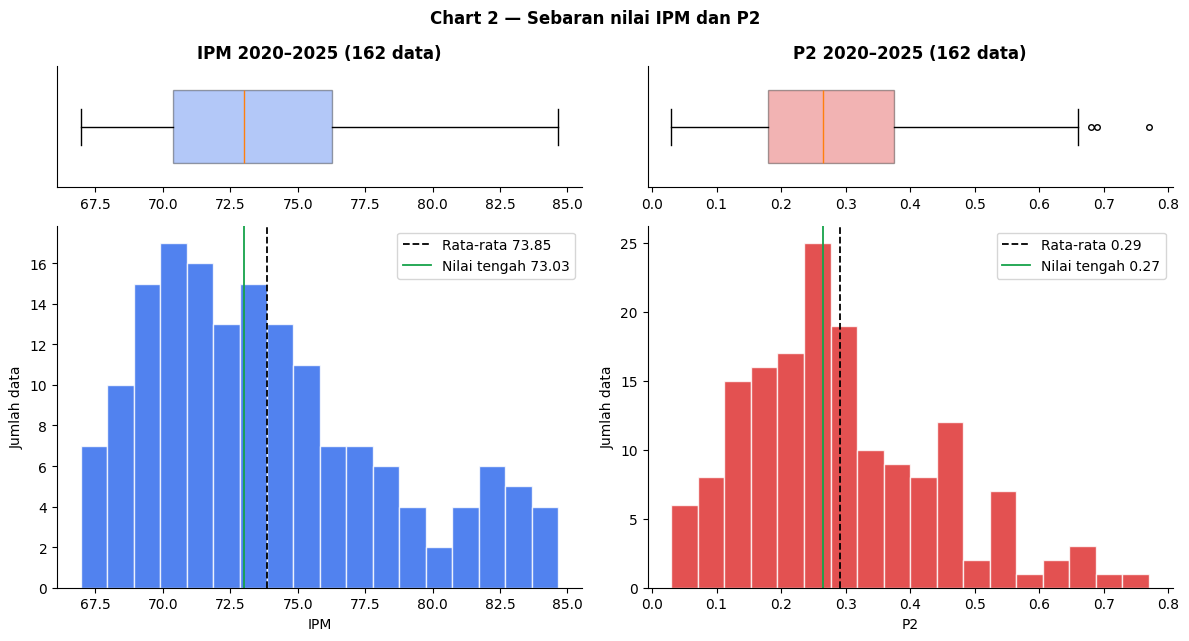

Interpretasi: IPM tidak punya data ekstrem (0), sedangkan P2 punya 3 data yang jauh lebih parah dari kebanyakan wilayah.
Data ekstrem tetap dipertahankan karena nilainya asli dari BPS, bukan kesalahan input.


In [79]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6.5), gridspec_kw={"height_ratios": [1, 3]})
for j, (k, nm, c) in enumerate([("ipm", "IPM", BIRU), ("p2", "P2", MERAH)]):
    v = master[k]
    axs[0, j].boxplot(v, vert=False, widths=0.6, patch_artist=True, boxprops=dict(facecolor=c, alpha=.35), flierprops=dict(marker="o", markersize=4))
    axs[0, j].set_yticks([]); axs[0, j].set_title(f"{nm} 2020–2025 ({len(v)} data)", fontweight="bold")
    axs[1, j].hist(v, bins=18, color=c, alpha=.8, edgecolor="white")
    axs[1, j].axvline(v.mean(), color="black", ls="--", lw=1.3, label=f"Rata-rata {v.mean():.2f}")
    axs[1, j].axvline(v.median(), color=HIJAU, ls="-", lw=1.3, label=f"Nilai tengah {v.median():.2f}")
    axs[1, j].set_xlabel(nm); axs[1, j].set_ylabel("Jumlah data"); axs[1, j].legend()
    axs[0, j].sharex(axs[1, j])
fig.suptitle("Chart 2 — Sebaran nilai IPM dan P2", fontweight="bold"); plt.tight_layout()
fig.savefig(f"{OUT_DIR}/chart2_sebaran_nilai.png", dpi=300, bbox_inches="tight"); plt.show()

print(f"Interpretasi: IPM tidak punya data ekstrem ({len(ekstrem['IPM'])}), sedangkan P2 punya {len(ekstrem['P2'])} data yang jauh lebih parah dari kebanyakan wilayah.")
print("Data ekstrem tetap dipertahankan karena nilainya asli dari BPS, bukan kesalahan input.")

### Chart 3 — Tren rata-rata Kabupaten vs Kota

### Penjelasan
- Dua panel berdampingan (IPM dan P2) dengan label angka per tahun untuk membandingkan dua kelompok wilayah.

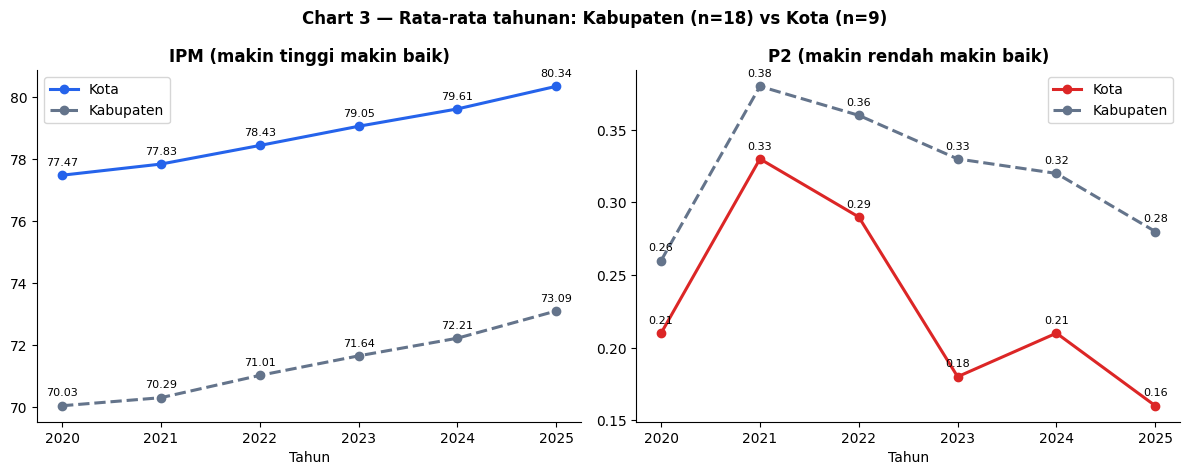

Interpretasi: Kota konsisten lebih tinggi IPM-nya (selisih rata-rata ±7.4 poin) dan P2-nya lebih rendah daripada Kabupaten;
keduanya sama-sama naik IPM-nya dari tahun ke tahun.


In [80]:
tren = master.groupby(["tahun", "tipe"])[["ipm", "p2"]].mean().round(2).unstack()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, k, nm in [(axs[0], "ipm", "IPM (makin tinggi makin baik)"), (axs[1], "p2", "P2 (makin rendah makin baik)")]:
    for tipe, c in [("Kota", MERAH if k == "p2" else BIRU), ("Kabupaten", ABU)]:
        ax.plot(tren.index, tren[(k, tipe)], marker="o", lw=2.2, color=c, label=tipe, ls="-" if tipe == "Kota" else "--")
        for t, v in tren[(k, tipe)].items(): ax.annotate(f"{v:.2f}", (t, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_title(nm, fontweight="bold"); ax.set_xticks(tren.index); ax.legend(); ax.set_xlabel("Tahun")
fig.suptitle("Chart 3 — Rata-rata tahunan: Kabupaten (n=18) vs Kota (n=9)", fontweight="bold"); plt.tight_layout()
fig.savefig(f"{OUT_DIR}/chart3_tren_kab_kota.png", dpi=300, bbox_inches="tight"); plt.show()

sel = (tren[("ipm", "Kota")] - tren[("ipm", "Kabupaten")]).mean()
print(f"Interpretasi: Kota konsisten lebih tinggi IPM-nya (selisih rata-rata ±{sel:.1f} poin) dan P2-nya lebih rendah daripada Kabupaten;")
print("keduanya sama-sama naik IPM-nya dari tahun ke tahun.")

---

## 8. Quality Assurance & Simpan Data Master

### Penjelasan
- 13 uji otomatis memastikan master benar: jumlah baris, duplikat, nilai kosong, kecocokan dengan data mentah, peringkat, kategori, status, dan koordinat.
- Master hanya disimpan bila **semua** uji lulus, sehingga file hasil selalu bisa dipercaya.

### Siapkan bahan uji

### Penjelasan
- Menghitung ulang nilai pembanding secara terpisah dari proses sebelumnya (bukan menyalin hasilnya) agar uji benar-benar independen.

In [81]:
per = master.groupby("tahun")["kode_kabupaten_kota"].nunique()
utama = ["kode_kabupaten_kota", "nama_label", "tipe", "tahun", "tanggal", "ipm", "p2", "kategori_ipm", "rank_ipm", "rank_p2",
         "ipm_rata2_kabkota", "p2_rata2_kabkota", "status_wilayah", "koordinat"]
yoy = ["ipm_yoy", "p2_yoy", "ipm_rata2_kabkota_yoy", "p2_rata2_kabkota_yoy"]
cek = (master.merge(ipm_raw[["kode_kabupaten_kota", "tahun", "indeks_pembangunan_manusia"]], on=["kode_kabupaten_kota", "tahun"], how="left")
             .merge(p2_raw[["kode_kabupaten_kota", "tahun", "indeks_keparahan_kemiskinan"]], on=["kode_kabupaten_kota", "tahun"], how="left"))

def rank_ok(c): return all(g[c].min() == 1 and g[c].between(1, 27).all() and len(g) == 27 for _, g in master.groupby("tahun"))

ulang = pd.Series(index=master.index, dtype=object)       # status dihitung ulang per tahun
for _, g in master.groupby("tahun"):
    a, b = g["ipm"] >= g["ipm"].mean(), g["p2"] <= g["p2"].mean()
    ulang[g.index] = np.select([a & b, a & ~b, ~a & b], ["Unggul", "Waspada kemiskinan", "Kejar IPM"], default="Tertinggal ganda")
kor = master["koordinat"].str.split(",", expand=True).astype(float)

### Jalankan 13 uji & simpan master

### Penjelasan
- Tiap uji mencetak ✔ (lulus) atau ✘ (gagal).

In [82]:
hasil = []
def uji(no, nama, lulus, info=""):
    hasil.append(bool(lulus)); print(f"{'✔' if lulus else '✘'} Uji {no:>2}: {nama}" + (f"  → {info}" if info else ""))

uji(1,  "Jumlah baris = 162", len(master) == 162, f"{len(master)} baris")
uji(2,  "27 wilayah per tahun", (per == 27).all() and len(per) == 6)
uji(3,  "Tidak ada duplikat wilayah+tahun", not master.duplicated(["kode_kabupaten_kota", "tahun"]).any())
uji(4,  "Tidak ada nilai kosong di kolom utama", master[utama].notna().all().all())
uji(5,  "Nilai IPM & P2 sama dengan data mentah BPS", np.isclose(cek["ipm"], cek["indeks_pembangunan_manusia"]).all() and np.isclose(cek["p2"], cek["indeks_keparahan_kemiskinan"]).all())
uji(6,  "Asal baris merge: 162 'both'", asal["both"] == 162 and asal["left_only"] == 0 and asal["right_only"] == 0)
uji(7,  "Kolom yoy kosong hanya di 2020", master.loc[master["tahun"] == 2020, yoy].isna().all().all() and master.loc[master["tahun"] > 2020, yoy].notna().all().all())
uji(8,  "Peringkat 1–27 lengkap tiap tahun", rank_ok("rank_ipm") and rank_ok("rank_p2"), "nilai sama = peringkat sama")
uji(9,  "Rentang nilai valid (IPM 0–100, P2 ≥ 0)", master["ipm"].between(0, 100).all() and (master["p2"] >= 0).all())
uji(10, "Kategori IPM konsisten", (master["kategori_ipm"] == master["ipm"].apply(kategori)).all())
uji(11, "Status wilayah konsisten", (ulang == master["status_wilayah"]).all())
uji(12, "Koordinat lengkap & di wilayah Jawa Barat", master["koordinat"].notna().all() and kor[0].between(-8, -5.5).all() and kor[1].between(105.5, 109).all())
uji(13, "27 kode wilayah cocok 100% dengan referensi resmi BPS (REF)",
    set(master["kode_kabupaten_kota"]) == set(REF) and (master["kode_kabupaten_kota"].map(REF).str.title().str.replace("Kabupaten ", "Kab. ") == master["nama_label"]).all())

print(f"\n{sum(hasil)} dari {len(hasil)} uji lulus.")
if all(hasil) and len(hasil) == 13:
    master.to_csv(f"{OUT_DIR}/master_ipm_p2_jabar.csv", index=False, encoding="utf-8-sig")
    print(f"Interpretasi: semua uji lulus, master disimpan ke {OUT_DIR}/master_ipm_p2_jabar.csv dan siap dianalisis.")
else:
    print("Interpretasi: ada uji gagal — master TIDAK disimpan. Periksa uji bertanda ✘ sebelum lanjut.")

✔ Uji  1: Jumlah baris = 162  → 162 baris
✔ Uji  2: 27 wilayah per tahun
✔ Uji  3: Tidak ada duplikat wilayah+tahun
✔ Uji  4: Tidak ada nilai kosong di kolom utama
✔ Uji  5: Nilai IPM & P2 sama dengan data mentah BPS
✔ Uji  6: Asal baris merge: 162 'both'
✔ Uji  7: Kolom yoy kosong hanya di 2020
✔ Uji  8: Peringkat 1–27 lengkap tiap tahun  → nilai sama = peringkat sama
✔ Uji  9: Rentang nilai valid (IPM 0–100, P2 ≥ 0)
✔ Uji 10: Kategori IPM konsisten
✔ Uji 11: Status wilayah konsisten
✔ Uji 12: Koordinat lengkap & di wilayah Jawa Barat
✔ Uji 13: 27 kode wilayah cocok 100% dengan referensi resmi BPS (REF)

13 dari 13 uji lulus.
Interpretasi: semua uji lulus, master disimpan ke hasil/master_ipm_p2_jabar.csv dan siap dianalisis.


---

## 9. Analisis Korelasi IPM–P2

### Penjelasan
- Korelasi bernilai −1 s.d. +1: **negatif** berarti IPM naik, P2 cenderung turun. **p < 0,05** = hubungan cukup meyakinkan.
- Pearson mengukur hubungan garis lurus; Spearman mengukur hubungan peringkat dan lebih tahan terhadap data ekstrem.
- Korelasi bukan bukti sebab-akibat.

### Fungsi korelasi per tahun

### Penjelasan
- Satu fungsi dipakai untuk semua wilayah maupun subset Kabupaten, supaya cara hitungnya sama.

In [83]:
def kekuatan(r):
    a = abs(r); return "sangat lemah" if a < .2 else "lemah" if a < .4 else "sedang" if a < .6 else "kuat" if a < .8 else "sangat kuat"

def korelasi_tahunan(df):
    out = []
    for t, g in df.groupby("tahun"):
        r, p = stats.pearsonr(g["ipm"], g["p2"]); rho, ps = stats.spearmanr(g["ipm"], g["p2"])
        out.append({"tahun": t, "n": len(g), "pearson_r": round(r, 3), "pearson_p": round(p, 4), "signifikan_pearson": "Ya" if p < .05 else "Tidak",
                    "spearman_rho": round(rho, 3), "spearman_p": round(ps, 4), "signifikan_spearman": "Ya" if ps < .05 else "Tidak",
                    "kekuatan_pearson": kekuatan(r)})
    return pd.DataFrame(out)

### Korelasi seluruh wilayah (n = 27)

### Penjelasan
- Hasil disimpan ke `korelasi_per_tahun.csv`.

In [84]:
kor_all = korelasi_tahunan(master)
kor_all.to_csv(f"{OUT_DIR}/korelasi_per_tahun.csv", index=False, encoding="utf-8-sig")
print(kor_all.to_string(index=False))

n_sig = int((kor_all["pearson_p"] < .05).sum())
print(f"\nInterpretasi: korelasi selalu negatif (r {kor_all['pearson_r'].iloc[0]:.2f} → {kor_all['pearson_r'].iloc[-1]:.2f}) dan signifikan pada {n_sig} dari {len(kor_all)} tahun.")

 tahun  n  pearson_r  pearson_p signifikan_pearson  spearman_rho  spearman_p signifikan_spearman kekuatan_pearson
  2020 27     -0.264     0.1828              Tidak        -0.171      0.3933               Tidak            lemah
  2021 27     -0.388     0.0458                 Ya        -0.386      0.0467                  Ya            lemah
  2022 27     -0.415     0.0315                 Ya        -0.343      0.0799               Tidak           sedang
  2023 27     -0.578     0.0016                 Ya        -0.526      0.0048                  Ya           sedang
  2024 27     -0.528     0.0046                 Ya        -0.482      0.0110                  Ya           sedang
  2025 27     -0.653     0.0002                 Ya        -0.678      0.0001                  Ya             kuat

Interpretasi: korelasi selalu negatif (r -0.26 → -0.65) dan signifikan pada 5 dari 6 tahun.


### Perbandingan rata-rata Kota vs Kabupaten

### Penjelasan
- Tabel rata-rata IPM dan P2 per tahun untuk dua kelompok wilayah.

In [85]:
banding = master.groupby(["tahun", "tipe"])[["ipm", "p2"]].mean().round(2).unstack()
banding.columns = [f"{a}_{b}" for a, b in banding.columns]
banding.to_csv(f"{OUT_DIR}/perbandingan_kota_kabupaten.csv", encoding="utf-8-sig")
print(banding.to_string())
print("\nInterpretasi: Kota selalu memiliki IPM lebih tinggi dan P2 lebih rendah dibanding Kabupaten di setiap tahun.")

       ipm_Kabupaten  ipm_Kota  p2_Kabupaten  p2_Kota
tahun                                                
2020           70.03     77.47          0.26     0.21
2021           70.29     77.83          0.38     0.33
2022           71.01     78.43          0.36     0.29
2023           71.64     79.05          0.33     0.18
2024           72.21     79.61          0.32     0.21
2025           73.09     80.34          0.28     0.16

Interpretasi: Kota selalu memiliki IPM lebih tinggi dan P2 lebih rendah dibanding Kabupaten di setiap tahun.


### Korelasi Pearson hanya Kabupaten (n = 18)

### Penjelasan
- Mengecek apakah hubungan IPM–P2 tetap ada tanpa Kota, yang nilainya cenderung ekstrem.

In [86]:
kor_kab = korelasi_tahunan(master[master["tipe"] == "Kabupaten"])[["tahun", "n", "pearson_r", "pearson_p", "signifikan_pearson", "kekuatan_pearson"]]
kor_kab.to_csv(f"{OUT_DIR}/korelasi_kabupaten_saja.csv", index=False, encoding="utf-8-sig")
print(kor_kab.to_string(index=False))
print(f"\nInterpretasi: tanpa Kota, hubungan signifikan pada {int((kor_kab['pearson_p'] < .05).sum())} dari {len(kor_kab)} tahun.")

 tahun  n  pearson_r  pearson_p signifikan_pearson kekuatan_pearson
  2020 18     -0.080     0.7526              Tidak     sangat lemah
  2021 18     -0.276     0.2671              Tidak            lemah
  2022 18     -0.124     0.6239              Tidak     sangat lemah
  2023 18     -0.228     0.3636              Tidak            lemah
  2024 18     -0.259     0.3000              Tidak            lemah
  2025 18     -0.520     0.0268                 Ya           sedang

Interpretasi: tanpa Kota, hubungan signifikan pada 1 dari 6 tahun.


---

## 10. Ringkasan Temuan Utama

### Penjelasan
- Empat temuan inti, dihitung langsung dari hasil di atas sehingga angkanya otomatis ikut berubah bila data diperbarui.

In [87]:
r_ = kor_all.set_index("tahun")["pearson_r"]; ipm_t = master.groupby("tahun")["ipm"].mean()
tg = master[(master["tahun"] == 2025) & (master["status_wilayah"] == "Tertinggal ganda")]
print(f"1. Pembangunan manusia naik: rata-rata IPM 27 kab/kota naik dari {ipm_t[2020]:.2f} (2020) menjadi {ipm_t[2025]:.2f} (2025).")
print(f"2. Kota selalu lebih unggul: IPM Kota rata-rata ±{sel:.1f} poin lebih tinggi dan kemiskinan (P2) lebih ringan daripada Kabupaten.")
print(f"3. Hubungan IPM–P2 selalu negatif dan cenderung makin kuat (r {r_[2020]:.2f} → {r_[2025]:.2f}); signifikan pada {n_sig} dari 6 tahun.")
print("   Artinya wilayah ber-IPM tinggi umumnya kemiskinannya lebih ringan, tetapi ini bukan bukti sebab-akibat.")
print(f"4. Pada 2025 ada {len(tg)} wilayah 'tertinggal ganda' (IPM di bawah rata-rata sekaligus P2 di atas rata-rata): {', '.join(tg['nama_label'])}.")

1. Pembangunan manusia naik: rata-rata IPM 27 kab/kota naik dari 72.51 (2020) menjadi 75.50 (2025).
2. Kota selalu lebih unggul: IPM Kota rata-rata ±7.4 poin lebih tinggi dan kemiskinan (P2) lebih ringan daripada Kabupaten.
3. Hubungan IPM–P2 selalu negatif dan cenderung makin kuat (r -0.26 → -0.65); signifikan pada 5 dari 6 tahun.
   Artinya wilayah ber-IPM tinggi umumnya kemiskinannya lebih ringan, tetapi ini bukan bukti sebab-akibat.
4. Pada 2025 ada 11 wilayah 'tertinggal ganda' (IPM di bawah rata-rata sekaligus P2 di atas rata-rata): Kab. Sukabumi, Kab. Cianjur, Kab. Garut, Kab. Tasikmalaya, Kab. Kuningan, Kab. Cirebon, Kab. Sumedang, Kab. Indramayu, Kab. Subang, Kab. Karawang, Kab. Bandung Barat.
